# Q-VNS: Learned Neighborhood Selection for the MVRDC
**ISE 571 Heuristic Search Methods, KFUPM. Term Project, Group 6:** Maha Abd Elhakeem, Sadia Waseem, Saphiah Bajba

This notebook accompanies our IEEE paper. It

1. loads the MVRDC benchmark of Masmoudi et al. (2026) [1];
2. **validates** our Python implementation against the authors' published solutions;
3. runs the baseline **MS-VNS** of [1] and our **Q-VNS** on one instance;
4. runs (or loads) the comparative experiment and analyses it (gap tables, Wilcoxon/Friedman tests, convergence, neighborhood usage, learned policy);
5. reports the parameter-sensitivity study and the small-instance check against CPLEX.

All algorithmic code lives in the `mvrdc/` package of the repository. This notebook only calls it.

## 0. Setup
On Colab this cell clones the repository, installs the requirements and downloads the benchmark. Locally it only fixes the working directory.

In [1]:
import os, sys
REPO_URL = "https://github.com/SadiaWaseem/571-Project.git"   # <-- set to the group repository
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/571-Project"):
        !git clone -q $REPO_URL /content/571-Project
    %cd /content/571-Project
    !pip -q install -r requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if not os.path.isdir("data/MVRDC/Instances"):
    !bash scripts/fetch_data.sh
sys.path.insert(0, os.getcwd())
DATA = "data/MVRDC"
print("working directory:", os.getcwd())

working directory: /home/claude/mvrdc-qvns


Optional: keep experiment results on Google Drive so that they survive a disconnected Colab session.

In [2]:
USE_DRIVE = False
RESULTS_ROOT = "results"
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_ROOT = "/content/drive/MyDrive/ISE571-QVNS/results"
os.makedirs(RESULTS_ROOT, exist_ok=True)

In [3]:
import json, glob, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mvrdc.instance import load_instance, list_instances
from mvrdc.solution import Evaluator, check_solution
from mvrdc.selectors import make_selector
from mvrdc.vns import VNSConfig, solve
from mvrdc import analysis as A, plots as P
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "font.size": 8})

## 1. Problem and data
The MVRDC [1] serves $n$ customers, each with fresh demand $q^1_i$, frozen demand $q^2_i$ and a time window $[e_i, l_i]$. The fleet has fresh vehicles, frozen vehicles and mixed-reconfigurable vehicles. A single-temperature vehicle may carry the other product in frigoboxes of capacity $w$, at most $F_k$ per vehicle and $F$ at the depot. A mixed vehicle picks one of $m_k$ predefined fresh/frozen splits before departure. The objective is lexicographic:

$$f(x) = 1000\,\#\text{vehicles} + \text{distance} + \theta\,\text{unused space},\qquad \theta = 1/\textstyle\sum_i (q^1_i+q^2_i).$$

The benchmark has 15 instances with 10, 15 and 20 customers (CPLEX comparison in [1]) and 60 instances with 200 customers in three fleet classes: A0 (small vehicles, 150–250), A1 (650–750) and A2 (950–1050).

In [4]:
rows = []
for size in ["10 customers", "15 customers", "20 customers", "200 customers"]:
    for p in list_instances(DATA, size):
        rows.append(load_instance(p).summary())
inst_table = pd.DataFrame(rows)
inst_table["class"] = inst_table["name"].str.extract(r"^(A\d)")
inst_table.groupby(["customers", "class"]).agg(
    instances=("name", "size"), fresh_units=("fresh_units", "mean"), frozen_units=("frozen_units", "mean"),
    mixed_units=("mixed_units", "mean"), frigoboxes=("frigoboxes", "mean"),
    fresh_demand=("fresh_demand", "mean"), frozen_demand=("frozen_demand", "mean")).round(1)

instances  fresh_units  frozen_units  mixed_units  frigoboxes  fresh_demand  frozen_demand
customers class                                                                                            
10        A0            15          2.0           2.0          2.0        10.0         102.7          119.5
15        A0            15          3.0           3.0          3.0        15.0         150.5          147.3
17        A0            10          3.0           2.9          3.0        15.0         198.6          214.1
18        A0             1          3.0           3.0          3.0        15.0         172.0          220.0
20        A0             4          3.0           3.0          3.0        15.0         178.2          244.0
200       A0            30         17.0          19.0         17.0        50.0        2069.1         2111.8
          A1            10         17.0          18.8         17.0        50.0        2144.5         2092.6
          A2            20         17.0          17.0         17.0        50.0        2126.0         2120.8

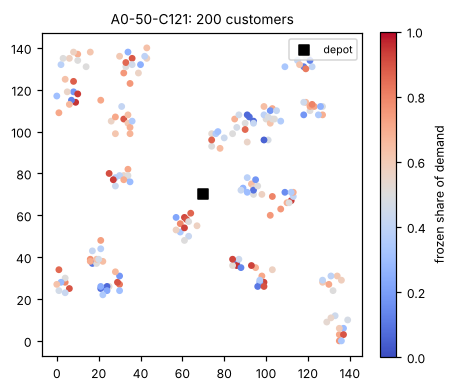

,unit,type,configs,F_k
0,1,fresh,"[(150, 0)]",1
1,2,fresh,"[(200, 0)]",2
2,3,fresh,"[(200, 0)]",2
3,4,fresh,"[(150, 0)]",1
4,5,fresh,"[(250, 0)]",2
5,6,fresh,"[(150, 0)]",1
6,7,fresh,"[(150, 0)]",1
7,8,fresh,"[(250, 0)]",2
8,9,fresh,"[(250, 0)]",2
9,10,fresh,"[(200, 0)]",1


In [5]:
inst = load_instance(f"{DATA}/Instances/200 customers/A0-50-C121.txt")
fig, ax = plt.subplots(1, 1, figsize=(4.2, 4))
P.plot_instance(inst, ax); plt.tight_layout(); plt.show()
pd.DataFrame([{"unit": u.uid, "type": u.kind, "configs": [c[1:] for c in u.configs], "F_k": u.max_frigo}
              for u in inst.units]).head(12)

## 2. Validation against the published results
Before comparing algorithms we check that our model is the authors' model. For every published route solution whose instance file is also published, we (i) audit feasibility independently (time windows, $T_{max}$, capacities, frigoboxes, one route per physical vehicle) and (ii) recompute the objective, then compare it with the value the authors report.

In [6]:
refs = A.published_references(DATA)
refs["diff"] = refs["ref_cost"] - refs["ref_reported"]
print(f"{len(refs)} published solutions checked")
print("max |recomputed - reported|:", refs["diff"].abs().max().round(3))
print("solutions with |diff| > 0.06:")
display(refs[refs["diff"].abs() > 0.06])

74 published solutions checked
max |recomputed - reported|: 0.998
solutions with |diff| > 0.06:


,instance,ref_cost,ref_reported,ref_vehicles,ref_distance,diff
8,A0-10-R127,2527.822204,2528.82,2,527.433316,-0.997796


All but one reported value agree to rounding. The exception, A0-10-R127, is reported exactly 1.0 above the cost of its own routes. The full list of data and code discrepancies is in `docs/DEVIATIONS.md`.

## 3. Algorithms
All compared methods share the MS-VNS of [1] (Algorithm 1): random multi-start construction (Alg. 2); shaking neighborhoods N1 swap, N2 relocate, N3 segment shift, N4 remove-insert; SelectBestVehicle (Alg. 3–4); local search (2-opt, relocate, 2-opt*, remove-two-insert-one); and Cauchy annealing acceptance. **They differ only in how the next neighborhood is chosen:**

| label | policy |
|---|---|
| `vns-fixed` | fixed order N1→N4, 5 attempts each |
| `ms-vns` | [1]: order re-sorted every 100 restarts by scores (1, 0, 5) |
| `vns-random` | uniform random, 20 steps per restart |
| `vns-n4` | ablation: N4 only |
| `vns-qmix` | ablation: fixed probabilities equal to Q-VNS's average shares in the pilot (oracle static mix) |
| `q-vns` | **ours**: ε-greedy tabular Q-learning, 20 steps per restart |

**Q-VNS.** State $s=(o, g, \phi, b)$: last outcome $o$ (improved / accepted worse / rejected or infeasible), stagnation $g$ (shaking steps since the last new best: $<20$, $<100$, $\ge 100$), search phase $\phi$ (thirds of the time budget) and frigobox use $b$ (boxes used by $x$ over $F$: $<0.5$, $<0.85$, $\ge 0.85$), giving 81 states. Action: $h\in\{N_1,\dots,N_4\}$. Reward: 5 / 2 / 0.5 / 0 / −1 for new best / improved / accepted / rejected / infeasible. Update:
$Q(s,h) \leftarrow Q(s,h) + \alpha\,[r + \gamma \max_{h'} Q(s',h') - Q(s,h)]$, with the last step of a restart terminal, $\alpha=0.1$, $\gamma=0.9$, and $\varepsilon$ decaying linearly from 0.3 to 0.05 over the budget.

### 3.1 One instance, one seed

In [7]:
DEMO_SECONDS = 30
demo = {}
for alg in ["ms-vns", "q-vns"]:
    demo[alg] = solve(inst, make_selector(alg), VNSConfig(time_limit=DEMO_SECONDS), seed=1)
    r = demo[alg]
    print(f"{alg:8s} cost={r.best_cost:10.2f} vehicles={r.vehicles} distance={r.distance:8.1f} "
          f"boxes={r.boxes} restarts={r.restarts} feasible={r.feasible}")
ref = refs.set_index("instance").loc[inst.name, "ref_cost"]
print(f"published solution of [1]: {ref:.2f}")

ms-vns   cost=  36866.11 vehicles=32 distance=  4865.6 boxes=47 restarts=243 feasible=True


q-vns    cost=  34495.55 vehicles=30 distance=  4495.1 boxes=45 restarts=181 feasible=True
published solution of [1]: 33994.51


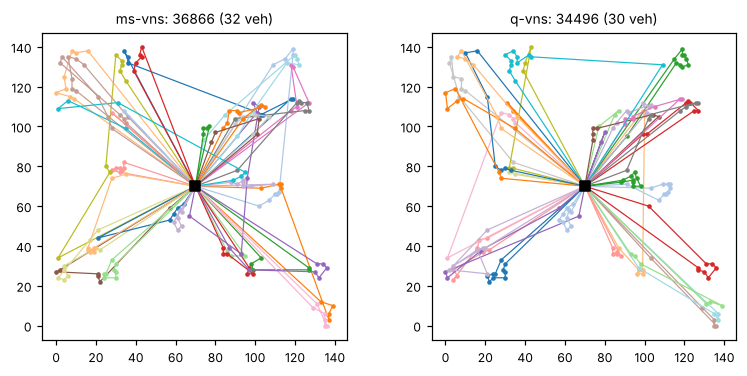

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4))
for ax, alg in zip(axes, demo):
    P.plot_routes(inst, demo[alg].routes, ax=ax, title=f"{alg}: {demo[alg].best_cost:.0f} ({demo[alg].vehicles} veh)")
plt.tight_layout(); plt.show()

## 4. Comparative experiment
**Protocol.** Each algorithm runs on every instance with the same wall-clock budget, the same seeds and identical components. We report the gap to the published solution of [1], $100\,(f - f_{[1]})/f_{[1]}$ (negative = better than [1]), as the best over seeds and the average over seeds. Q-VNS is compared with each rival by a paired Wilcoxon signed-rank test on per-instance mean costs (Holm-corrected), and all methods together by a Friedman test.

Set `RUN_EXPERIMENTS = True` to run the experiment here (resumable). With the default `False`, the results already stored in the repository are loaded.

In [9]:
RUN_EXPERIMENTS = False
EXP_DIR = f"{RESULTS_ROOT}/main"
if RUN_EXPERIMENTS:
    !python experiments/run.py --data $DATA --sizes "200 customers" \
        --algorithms vns-fixed ms-vns vns-random vns-n4 vns-qmix q-vns --seeds 1-10 --time-limit 60 \
        --workers 2 --out $EXP_DIR
if not os.path.exists(f"{EXP_DIR}/results.csv"):
    EXP_DIR = "results/pilot"          # fall back to the pilot study shipped with the repo
print("using", EXP_DIR, json.load(open(f"{EXP_DIR}/config.json"))["vns"])

using results/pilot {'time_limit': 30.0, 'max_restarts': None}


In [10]:
res = A.add_gaps(A.load_results(EXP_DIR), refs)
print(len(res), "runs;", res["instance"].nunique(), "instances;", "all feasible:", bool(res["feasible"].all()))
A.summary_table(res)

126 runs; 6 instances; all feasible: True


,algorithm,instances,best_gap,avg_gap,sd_gap,vehicles,time_to_best,restarts,all_feasible
3,vns-fixed,6,2.486,5.844,3.045,19.778,4.045,254.278,True
0,ms-vns,6,2.497,4.949,2.383,19.556,7.790,250.278,True
1,ms-vns-code,6,2.890,5.820,2.852,19.722,4.618,248.000,True
6,vns-random,6,2.173,3.865,1.640,19.278,12.889,252.111,True
4,vns-n4,6,-5.355,-4.137,1.151,18.222,15.966,83.667,True
5,vns-qmix,6,-1.040,0.069,1.242,18.778,14.665,136.778,True
2,q-vns,6,-4.657,-2.754,2.119,18.389,17.158,142.556,True


In [11]:
A.summary_table(res, by=["family"])

,family,algorithm,instances,best_gap,avg_gap,sd_gap,vehicles,time_to_best,restarts,all_feasible
3,A0-C,vns-fixed,1,6.070,7.465,1.242,31.333,0.321,223.000,True
0,A0-C,ms-vns,1,6.070,7.465,1.242,31.333,0.232,215.667,True
1,A0-C,ms-vns-code,1,6.070,7.465,1.242,31.333,0.228,225.333,True
6,A0-C,vns-random,1,3.513,6.901,3.092,30.667,10.214,217.000,True
4,A0-C,vns-n4,1,-2.200,-1.852,0.304,29.000,13.844,85.000,True
5,A0-C,vns-qmix,1,-0.106,1.079,1.027,29.667,16.305,131.000,True
2,A0-C,q-vns,1,-4.017,-1.204,2.943,29.000,14.184,142.667,True
10,A0-R,vns-fixed,1,4.789,8.087,3.061,30.000,9.376,225.333,True
7,A0-R,ms-vns,1,4.789,7.770,2.607,29.667,14.308,228.333,True
8,A0-R,ms-vns-code,1,4.789,8.847,3.515,30.333,1.723,194.000,True


In [12]:
display(A.wins_table(res, "q-vns"))
sig = A.significance(res, "q-vns")
display(sig)
print("Friedman:", sig.attrs.get("friedman"))

,vs,better,equal,worse
0,ms-vns,6,0,0
1,ms-vns-code,6,0,0
2,vns-fixed,6,0,0
3,vns-n4,1,0,5
4,vns-qmix,5,0,1
5,vns-random,6,0,0


,vs,n_instances,median_diff,mean_diff,W,p,p_holm
0,ms-vns,6,-1551.172150,-1624.832822,0.0,0.03125,0.18750
1,ms-vns-code,6,-1601.906450,-1746.604606,0.0,0.03125,0.18750
2,vns-fixed,6,-1486.467350,-1724.964367,0.0,0.03125,0.18750
3,vns-random,6,-1191.312217,-1420.638217,0.0,0.03125,0.18750
4,vns-qmix,6,-575.426133,-451.622678,1.0,0.06250,0.18750
5,vns-n4,6,226.535050,205.479833,4.0,0.21875,0.21875


Friedman: {'chi2': 30.80733944954129, 'p': 2.7588893233578365e-05, 'algorithms': ['ms-vns', 'ms-vns-code', 'q-vns', 'vns-fixed', 'vns-n4', 'vns-qmix', 'vns-random'], 'instances': 6}


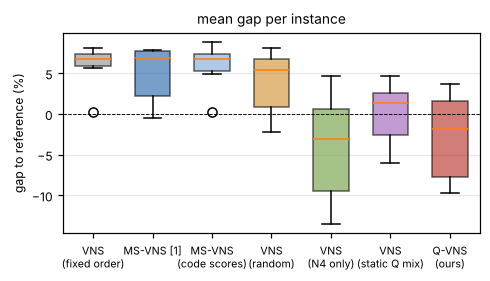

In [13]:
fig, ax = plt.subplots(figsize=(4.5, 2.6))
P.plot_gap_box(res.groupby(["instance", "algorithm"], as_index=False)["gap"].mean(), ax=ax)
ax.set_title("mean gap per instance", fontsize=9); plt.tight_layout(); plt.show()

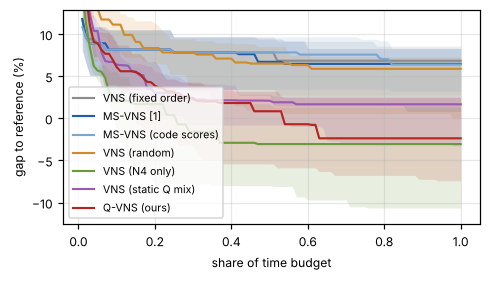

In [14]:
runs = A.load_runs(EXP_DIR)
refmap = refs.set_index("instance")["ref_cost"].to_dict()
conv = A.convergence(runs, refmap, np.linspace(0, 1, 101))
fig, ax = plt.subplots(figsize=(4.5, 2.6))
P.plot_convergence(conv, ax=ax); ax.set_ylim(top=conv[conv.t >= 0.05]["gap"].quantile(0.99))
plt.tight_layout(); plt.show()

### 4.1 Where does the effort go?
Share of shaking steps given to each neighborhood, and how often each neighborhood produced no feasible move.

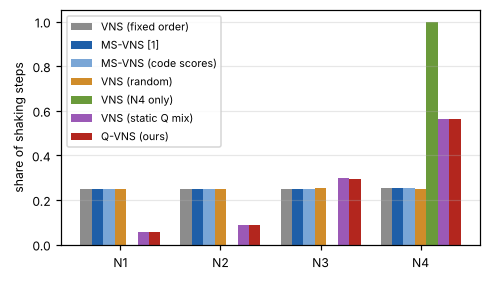

picks                                                         infeasible_%                                                        improved_%  \
algorithm    ms-vns ms-vns-code  q-vns vns-fixed vns-n4 vns-qmix vns-random       ms-vns ms-vns-code q-vns vns-fixed vns-n4 vns-qmix vns-random     ms-vns   
neighborhood                                                                                                                                                 
N1            22512       22309   2786     22886      0     2674      22599         81.1        82.4  76.2      85.9    NaN     76.5       77.3       12.0   
N2            22568       22367   4621     22932      0     4285      22478         56.1        54.4  48.9      56.2    NaN     54.1       53.2       33.2   
N3            22615       22397  16274     22961      0    14611      22785         26.7        29.1  10.1      29.0    NaN     27.1       27.6       59.0   
N4            23034       22816  27467     23396  29933    27489      22687          0.1         0.9   0.6       0.1    1.2      0.5        0.7       97.9   

                                                                     
algorithm    ms-vns-code q-vns vns-fixed vns-n4 vns-qmix vns-random  
neighborhood                                                         
N1                  10.3  11.1      11.5    NaN     11.4       12.1  
N2                  32.6  33.2      35.4    NaN     27.2       31.6  
N3                  52.3  64.8      54.9    NaN     51.0       53.5  
N4                  97.8  89.7      97.9   83.3     91.3       97.3

In [15]:
usage = A.neighborhood_usage(runs)
fig, ax = plt.subplots(figsize=(4.5, 2.6)); P.plot_usage(usage, ax=ax); plt.tight_layout(); plt.show()
u = usage.groupby(["algorithm", "neighborhood"])[["picks", "new_best", "improved", "accepted", "rejected", "infeasible"]].sum()
u["infeasible_%"] = (100 * u["infeasible"] / u["picks"]).round(1)
u["improved_%"] = (100 * (u["new_best"] + u["improved"]) / u["picks"]).round(1)
u[["picks", "infeasible_%", "improved_%"]].unstack(0)

### 4.2 What did the agent learn?
Q-values at the end of one run (rows: visited states, encoded as outcome, stagnation, phase, boxes).

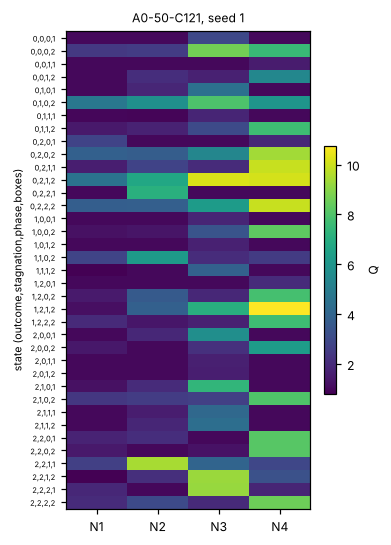

In [16]:
qrun = next(r for r in runs if r["algorithm"] == "q-vns")
fig, ax = plt.subplots(figsize=(3.6, 5)); P.plot_q_policy(qrun["selector_stats"]["q_table"], ax=ax)
ax.set_title(f'{qrun["instance"]}, seed {qrun["seed"]}', fontsize=8); plt.tight_layout(); plt.show()

## 5. Parameter sensitivity of Q-VNS
One parameter is varied at a time around the default ($\alpha=0.1$, $\gamma=0.9$, $\varepsilon_0=0.3$), on a subset of instances. Each setting is stored in its own folder `results/sens_<name>`. Example:

```bash
python experiments/run.py --data data/MVRDC --instances "A0-50-*1" --algorithms q-vns \
    --seeds 1-5 --time-limit 60 --out results/sens_alpha0.3 --q alpha=0.3
```

In [17]:
rows = []
for d in sorted(glob.glob(f"{RESULTS_ROOT}/sens_*")) + sorted(glob.glob("results/sens_*")):
    if os.path.exists(f"{d}/results.csv"):
        s = A.add_gaps(A.load_results(d), refs)
        rows.append({"setting": os.path.basename(d), "runs": len(s), "best_gap": s.groupby("instance")["gap"].min().mean(),
                     "avg_gap": s["gap"].mean(), "vehicles": s["vehicles"].mean()})
pd.DataFrame(rows).round(3) if rows else print("no sensitivity results found yet")

no sensitivity results found yet


## 6. Small instances: comparison with CPLEX
In [1], CPLEX (4 h limit) proves optimality on all 10-customer instances. On the 10-customer instances, the optimum equals the published solution, so a gap of 0 means the optimum was found.

In [18]:
SMALL_SECONDS = 5
small = []
for p in list_instances(DATA, "10 customers"):
    I = load_instance(p)
    for alg in ["ms-vns", "q-vns"]:
        r = solve(I, make_selector(alg), VNSConfig(time_limit=SMALL_SECONDS), seed=1)
        small.append({"instance": I.name, "algorithm": alg, "best_cost": r.best_cost,
                      "time_to_best": r.time_to_best, "feasible": r.feasible})
small = pd.DataFrame(small).merge(refs[["instance", "ref_cost"]], on="instance", how="left")
small["gap"] = 100 * (small["best_cost"] - small["ref_cost"]) / small["ref_cost"]
small.pivot(index="instance", columns="algorithm", values="gap").round(3)

algorithm,ms-vns,q-vns
instance,,
A0-10-C121,-0.000,-0.000
A0-10-C123,-0.000,-0.000
A0-10-C124,-0.000,-0.000
A0-10-C127,NaN,NaN
A0-10-C129,0.008,0.008
A0-10-R121,0.000,0.000
A0-10-R1210,-0.000,-0.000
A0-10-R122,0.009,0.009
A0-10-R126,-0.008,-0.008


## 7. Notes for the discussion section
* Report gaps relative to the published solutions of [1] **and** state that [1] ran C++ for up to 100,000 restarts (CPU times in their Table E1), whereas every method here has the same Python time budget.
* The comparison that isolates *learning* is **Q-VNS vs. VNS-random**: both reallocate effort across neighborhoods with the same step budget, and only Q-VNS learns. **Q-VNS vs. VNS (static Q mix)** separates the *overall allocation* from the *state-dependent* part of the policy. **Q-VNS vs. MS-VNS** measures the full replacement of the score-based re-ordering.
* Section 4.1 shows how much of the sweep's budget is spent on shakes that find no feasible move. This is the mechanism a fixed re-ordering cannot address.
* Paper-vs-code differences of [1] that affect the baseline are listed in `docs/DEVIATIONS.md`.